Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.9520 - loss: 0.1590 - val_accuracy: 0.9828 - val_loss: 0.0631
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9833 - loss: 0.0542 - val_accuracy: 0.9857 - val_loss: 0.0519
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9898 - loss: 0.0329 - val_accuracy: 0.9838 - val_loss: 0.0593
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9927 - loss: 0.0225 - val_accuracy: 0.9880 - val_loss: 0.0527
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9944 - loss: 0.0158 - val_accuracy: 0.9895 - val_loss: 0.0457
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9864 - loss: 0.0435
Test Loss: 0.04351402074098587
Test Accuracy: 98.64000082015991 %


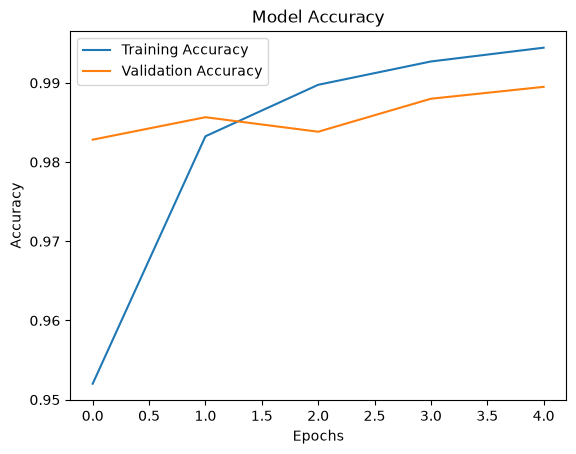

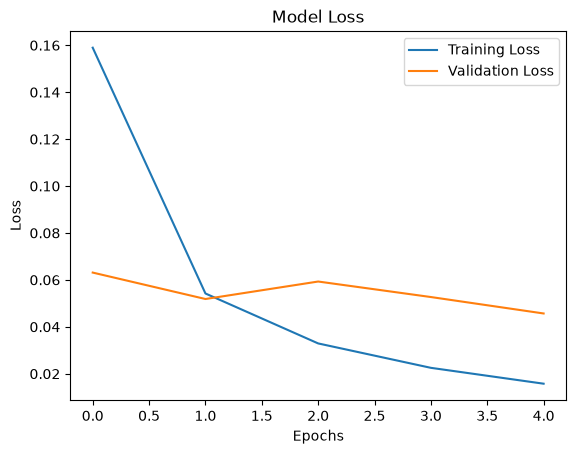

In [1]:

# --------------------------------------------------
# PRACTICAL 2B: CNN FOR HANDWRITTEN MNIST
# --------------------------------------------------

# STAGE 1: Loading and preprocessing data

# 1. Import libraries
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

# 2. Load local MNIST CSV files
train_data = pd.read_csv("mnist_train.csv")
test_data = pd.read_csv("mnist_test.csv")

# 3. Separate images and labels
x_train = train_data.iloc[:, 1:].values
y_train = train_data.iloc[:, 0].values

x_test = test_data.iloc[:, 1:].values
y_test = test_data.iloc[:, 0].values

# 4. Normalize pixel values
x_train = x_train / 255.0
x_test = x_test / 255.0

# 5. Reshape images for CNN
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)


# STAGE 2: Define CNN architecture

model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(28, 28, 1)),

    # Extract image features
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),

    # Reduce image size
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convert feature maps into one-dimensional data
    tf.keras.layers.Flatten(),

    # Hidden layer
    tf.keras.layers.Dense(128, activation='relu'),

    # Output layer for 10 digits
    tf.keras.layers.Dense(10, activation='softmax')
])


# STAGE 3: Compile and train the model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train, y_train,
    epochs=5,
    validation_split=0.1
)


# STAGE 4: Evaluate model performance

loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")


# Plot accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


# Plot loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


# Practical 2B – CNN for Handwritten MNIST Image Classification

## Problem statement

2B. Implement the Image classification CNN model for classifying hand-written MNIST dataset by dividing the model into following 4 stages:

a. Loading and preprocessing the image data\
b. Defining the model's architecture\
c. Training the model\
d. Estimating the model's performance

Easy–Medium

## 1. Understand the practical

[MNIST 图像分类 — Jittor](https://images.openai.com/static-rsc-4/LsMz6cD1vKONDgD93wFq2PUuELmFV_8cv3M4RdUNmKomf5dG5FoT56420xJg6FSPQFepcT2MGMXvIkTqNJ212utzWZcscYxt1yDpnGYEb6mDOgT9W4-gJsr43xt031cSMhE-amJfwEDCBnciJGaZaOtMifa6vkm7pMvzObn8ClI?purpose=inline)

[cg.cs.tsinghua.edu.cn](https://cg.cs.tsinghua.edu.cn/jittor/2020/03/15/mnistclassification/?utm_source=chatgpt.com)

What is MNIST?

MNIST is a dataset containing handwritten digits from 0 to 9.

- Total training images: 60,000
- Total testing images: 10,000
- Image size: 28 × 28 pixels
- Colour: Grayscale
- Number of classes: 10 (digits 0–9)

Objective: Build a CNN model that looks at a handwritten digit and predicts which number it represents.

For example, input an image of handwritten `7` → model predicts `7`.

## 2. Stage 1 – Loading and preprocessing data

### Import libraries

```
import tensorflow as tfimport pandas as pdimport matplotlib.pyplot as plt
```

- TensorFlow: Builds and trains the CNN.
- Pandas: Loads CSV datasets.
- Matplotlib: Displays graphs.

### Load local dataset

```
train_data = pd.read_csv("mnist_train.csv")test_data = pd.read_csv("mnist_test.csv")
```

We load our local training and testing CSV files.

Why local CSV? Because your dataset is already downloaded; we don't need TensorFlow's built-in dataset loader.

### Separate images and labels

```
x_train = train_data.iloc[:, 1:].valuesy_train = train_data.iloc[:, 0].valuesx_test = test_data.iloc[:, 1:].valuesy_test = test_data.iloc[:, 0].values
```

Here:

- `x_train` = Training images (pixel values).
- `y_train` = Correct training labels (digits).
- `x_test` = Testing images.
- `y_test` = Correct testing labels.

Why `iloc[:, 1:]`?

- `:` means select all rows.
- `1:` means select columns starting from index 1.
- Column 0 contains the digit label, so we exclude it.

### Normalize pixel values

```
x_train = x_train / 255.0x_test = x_test / 255.0
```

Pixel values range from 0 to 255.

Dividing by 255 converts them into values between 0 and 1.

This helps the model train more effectively.

### Reshape images

```
x_train = x_train.reshape(-1, 28, 28, 1)x_test = x_test.reshape(-1, 28, 28, 1)
```

This is very important for CNN.

- `-1` = Automatically calculates the number of images.
- `28` = Image height.
- `28` = Image width.
- `1` = One colour channel (grayscale).

Why 1 channel?

MNIST images are grayscale, unlike CIFAR-10 images, which are RGB and have 3 channels.

## 3. Stage 2 – Define CNN architecture

Your CNN architecture is:

Input image

28 × 28 × 1

Conv2D

32 filters, 3 × 3, ReLU

MaxPooling2D

2 × 2

Flatten

Converts feature maps into 1D

Dense layer

128 neurons, ReLU

Output layer

10 neurons, Softmax

Predicted digit: 0–9

### Understand each layer

1\. Input layer

```
tf.keras.layers.Input(shape=(28, 28, 1)),
```

Specifies that the input image is 28 × 28 with one grayscale channel.

2\. Convolution layer

```
tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
```

- `Conv2D`: Extracts features from images.
- `32`: Number of filters.
- `(3,3)`: Filter size.
- `relu`: Activation function.

It detects features such as edges, curves and shapes in handwritten digits.

3\. MaxPooling layer

```
tf.keras.layers.MaxPooling2D((2, 2)),
```

Reduces the feature map size by selecting maximum values from 2 × 2 regions.

It reduces computation and keeps important features.

4\. Flatten layer

```
tf.keras.layers.Flatten(),
```

Converts the extracted feature maps into a one-dimensional array so that Dense layers can process them.

5\. Dense layer

```
tf.keras.layers.Dense(128, activation='relu'),
```

Contains 128 neurons and learns from the features extracted by the CNN.

6\. Output layer

```
tf.keras.layers.Dense(10, activation='softmax')
```

Contains 10 neurons because we have 10 possible digits (0–9).

Softmax gives probabilities for each digit. The highest probability becomes the predicted digit.

## 4. Stage 3 – Compile and train the model

### Compile

```
model.compile(    optimizer='adam',    loss='sparse_categorical_crossentropy',    metrics=['accuracy'])
```

| Parameter                       | Meaning                                                |
| ------------------------------- | ------------------------------------------------------ |
| Adam                            | Optimizer that updates weights                         |
| Sparse categorical crossentropy | Loss function for multiple classes with integer labels |
| Accuracy                        | Measures correct predictions                           |

### Train

```
history = model.fit(    x_train, y_train,    epochs=5,    validation_split=0.1)
```

- `x_train`: Training images.
- `y_train`: Correct digit labels.
- `epochs=5`: Model sees the training dataset 5 times.
- `validation_split=0.1`: Uses 10% of training data for validation.

What is validation?

It checks how well the model performs on data that is not being used to update its weights during training.

`history` stores the training and validation accuracy and loss for plotting.

## 5. Stage 4 – Evaluate model performance

```
loss, accuracy = model.evaluate(x_test, y_test)
```

Tests the trained model on unseen testing images.

```
print("Test Loss:", loss)print("Test Accuracy:", accuracy * 100, "%")
```

- Loss: Measures prediction error.
- Accuracy: Percentage of correctly classified images.

### Accuracy graph

```
plt.plot(history.history['accuracy'], label='Training Accuracy')plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
```

Shows how training and validation accuracy change over epochs.

### Loss graph

```
plt.plot(history.history['loss'], label='Training Loss')plt.plot(history.history['val_loss'], label='Validation Loss')
```

Shows how training and validation loss change over epochs.

Remember: Ideally, accuracy increases and loss decreases. If training accuracy is high but validation accuracy is much lower, the model may be overfitting.

## 6. Important viva questions

| Question                   | Answer                                                          |
| -------------------------- | --------------------------------------------------------------- |
| What is CNN?               | Convolutional Neural Network, mainly used for image processing. |
| What is MNIST?             | A handwritten digit dataset containing digits 0–9.              |
| What is the image size?    | 28 × 28 pixels.                                                 |
| Why is the channel size 1? | Because MNIST images are grayscale.                             |
| Why use Conv2D?            | To extract image features.                                      |
| What is a filter?          | A small matrix that detects features in an image.               |
| Why use MaxPooling?        | To reduce feature map dimensions.                               |
| What is Flatten?           | Converts feature maps into a 1D vector.                         |
| Why 10 output neurons?     | There are 10 digit classes.                                     |
| What is ReLU?              | An activation function that changes negative values to zero.    |
| What is Softmax?           | Converts output values into class probabilities.                |
| What is an epoch?          | One complete pass through the training dataset.                 |
| What is overfitting?       | Good training performance but poor performance on unseen data.  |

## 7. Short explanation to speak in the practical exam

"In this practical, I implemented a CNN model for handwritten digit classification using the MNIST dataset.

First, I loaded the local training and testing CSV files. I separated images and labels, normalized pixel values between 0 and 1, and reshaped images into 28 × 28 grayscale format.

Then, I created a CNN architecture using one convolution layer with 32 filters, one MaxPooling layer, a Flatten layer, a Dense layer with 128 neurons and an output layer with 10 neurons.

I compiled the model using Adam optimizer and sparse categorical crossentropy loss. Then I trained it for 5 epochs using 10% validation data.

Finally, I evaluated the model on testing data and plotted accuracy and loss graphs to check its performance."

## 8. Quick revision

| Parameter      | Value   |
| -------------- | ------- |
| Dataset        | MNIST   |
| Image size     | 28 × 28 |
| Channels       | 1       |
| Classes        | 10      |
| Conv2D filters | 32      |
| Filter size    | 3 × 3   |
| Pooling        | 2 × 2   |
| Dense neurons  | 128     |
| Output neurons | 10      |
| Optimizer      | Adam    |
| Epochs         | 5       |
| Validation     | 10%     |

Important difference from Practical 2A:

- 2A CIFAR-10: RGB images, input shape `(32, 32, 3)`.
- 2B MNIST: Grayscale images, input shape `(28, 28, 1)`.

The CNN architecture is almost the same, but the dataset and input dimensions are different.